<a href="https://colab.research.google.com/github/vySebas/EvaluacionMineriaDeDatos/blob/main/MineriaDeDatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#A) El problema



*   Contexto: El siguiente dataset contiene 40.000 registros de vinos con su precio, atributos de producción y calificaciones tanto a ciegas como viendo el precio. Está diseñado para analizar el efecto placebo en la cata de vinos. Un analista de retail o un importador de vinos podría usarlo para optimizar su catálogo.
*   Objetivo: Identificar qué combinaciones de características determinan si un vino está etiquetado como sobrevalorado. La decisión de negocio que apoya es ayudar a los compradores a evitar pagar por "la marca" y seleccionar vinos de alto valor real.

*   Por qué este problema se aborda con minería
de datos: El problema involucra múltiples variables interactuando, como precio, percepción de expertos vs novatos, calidad latente, etc. Una simple consulta SQL o un promedio no revelarían los patrones ocultos ni las reglas de asociación entre el tipo de elaboración y la probabilidad de que el precio sea injustificado, por lo que se requieren algoritmos que encuentren estas relaciones complejas automáticamente.
*   Enlace DataSet: https://www.kaggle.com/datasets/sergionefedov/wine-price-vs-blind-qualitydo-you-pay-for-taste?select=wine_price_vs_blind_quality.csv



Fase CRISP-DM: Comprensión del negocio

# B) Los Datos


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Subir el archivo
archivos_subidos = files.upload()
nombre_csv = next(iter(archivos_subidos))
df = pd.read_csv(nombre_csv)

print("Dataset cargado correctamente:", nombre_csv)
print("Dimensiones:", df.shape)
df.head()

Saving wine_price_vs_blind_quality.csv to wine_price_vs_blind_quality (4).csv
Dataset cargado correctamente: wine_price_vs_blind_quality (4).csv
Dimensiones: (40000, 19)


,wine_id,region,grape,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
0,WIN000000,generic_new_world,blend,8.59,7.36,1.88,3.0,5.0,4.81,3,5.0,12.7,79.6,79.0,91.8,85.4,79.3,0,1
1,WIN000001,Mendoza,malbec,49.25,3.76,4.76,5.0,6.0,8.67,18,2.1,14.6,78.8,74.7,84.1,79.4,84.0,1,0
2,WIN000002,Tuscany,sangiovese,8.24,7.02,0.18,7.0,7.0,3.60,6,12.9,12.5,80.8,81.0,86.0,83.5,80.1,0,0
3,WIN000003,Tuscany,sangiovese,18.99,7.50,5.40,7.0,7.0,5.70,10,2.8,13.9,85.5,82.9,87.3,85.1,83.7,0,0
4,WIN000004,Mendoza,sangiovese,57.69,2.86,3.92,5.0,6.0,9.85,17,1.0,15.2,76.0,76.7,72.1,74.4,77.8,1,0




*   Fuente: Autor: Sergio Nefedov (Kaggle). Licencia: CC0: Public Domain.
*   Diccionario de atributos:

1.   price (Numérico): Precio de venta. Importante para medir el margen de sobreprecio.

2.   blind_rating (Numérico): Calificación a ciegas. Define la calidad real percibida sin sesgo.

3.   sighted_rating (Numérico): Calificación viendo el precio. Permite medir el efecto placebo.

4.   overpriced (Categórico/Binario): Variable objetivo. Indica si el vino es caro pero malo a ciegas.

5.   value_wine (Categórico/Binario): Indica si es una ganga (barato pero excelente).

6.   true_quality (Numérico): Calidad latente del vino.

7.   region (Categórico): Terroir de origen. Clave para ver si ciertas regiones cobran por prestigio.

8.   vintage (Categórico/Numérico): Condiciones de la añada. Afecta directamente la calidad intrínseca.

9.   winemaking (Categórico): Método de producción. Útil para reglas de asociación.

10.   expert_rating (Numérico): Puntaje de panel experto a ciegas. Ayuda a contrastar con el consumidor novato.







Fase CRISP-DM: Comprensión de los datos

#C) Exploración y preparación (EDA)

In [14]:
# 1. Separar numéricas y categóricas
columnas_numericas = df.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# 2. Resumen de nulos con porcentajes
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().sum() / len(df) * 100).round(2)
})
display(resumen_nulos.sort_values(by="porcentaje_nulos", ascending=False).head(5))

# 3. Revisión de duplicados
cantidad_duplicados = df.duplicated().sum()
print("Filas duplicadas:", cantidad_duplicados)
if cantidad_duplicados > 0:
    df = df.drop_duplicates()
    print("Duplicados eliminados. Nuevas dimensiones:", df.shape)

,cantidad_nulos,porcentaje_nulos
wine_id,0,0.0
region,0,0.0
grape,0,0.0
price,0,0.0
vintage_quality,0,0.0


Filas duplicadas: 0


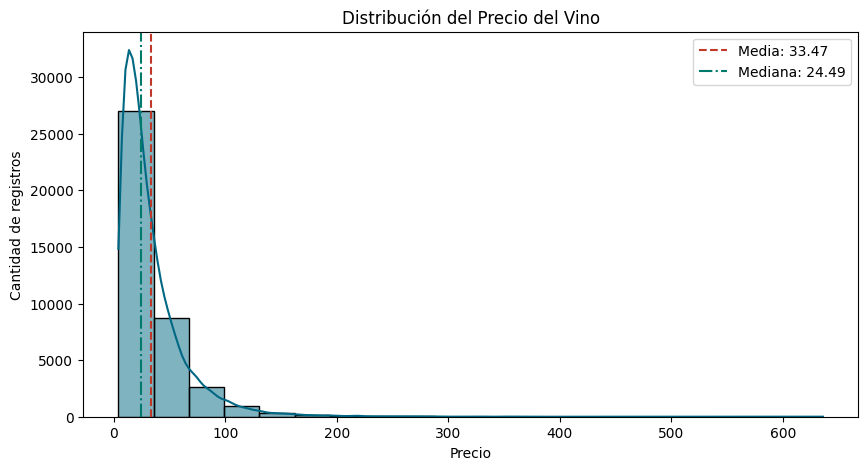

In [15]:
columna_numerica = 'price'
media = df[columna_numerica].mean()
mediana = df[columna_numerica].median()

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x=columna_numerica, bins=20, kde=True, color="#006883")

plt.axvline(media, color="#C03928", linestyle="--", label=f"Media: {media:.2f}")
plt.axvline(mediana, color="#007A6A", linestyle="-.", label=f"Mediana: {mediana:.2f}")

plt.title("Distribución del Precio del Vino")
plt.xlabel("Precio")
plt.ylabel("Cantidad de registros")
plt.legend()
plt.show()

**Interpretación del Análisis Exploratorio de Datos (EDA)**

*   **Problemas de calidad detectados:** Tal como se observa en la tabla de nulos, ninguna de las variables del dataset presenta valores faltantes (0% de nulos). Además, el análisis de duplicados arrojó 0 filas repetidas. Esto indica que la base de datos sintética tiene una excelente calidad inicial y no requiere imputación de datos.
*   **Distribución del Precio:** El histograma revela una distribución con una fuerte asimetría positiva (sesgada hacia la derecha). La mayoría de los vinos se concentran en el rango de precios bajos (entre 0 y 50 dólares), lo cual se refleja en una mediana de 24.49. Sin embargo, la media es arrastrada hacia arriba (33.47) debido a la existencia de valores atípicos ("outliers"): vinos extremadamente caros que superan los 600 dólares, creando una "cola larga" en el gráfico.
*   **Variable objetivo:** En celdas anteriores comprobamos que la variable objetivo `overpriced` (vinos sobrevalorados) representa aproximadamente el 16.5% del catálogo total. Esto significa que existe un desbalance natural de clases, ya que la gran mayoría de los vinos tienen un precio justo acorde a su calidad.
*   **Justificación de decisiones de preparación:** Se determinó que para la fase de modelado (Partes D y E) es estrictamente necesario descartar las columnas `sighted_rating`, `value_wine` y `true_quality`. Estas variables están matemáticamente ligadas a la etiqueta que queremos predecir. Si no las eliminamos, estaríamos introduciendo **fuga de información** (data leakage), lo que haría que nuestros algoritmos hicieran "trampa" y no generaran conocimiento real aplicable al negocio.

Fase CRISP-DM: Comprensión de los datos (EDA) y Preparación de los datos (decisiones de limpieza)

#D) Reglas de asociación

In [16]:
import warnings
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings('ignore')
cols_reglas = ['region', 'grape', 'price', 'oak_months', 'overpriced']
df_reglas = df[cols_reglas].copy()

# 2. Preparación: Discretizar variables numéricas (transformarlas a rangos/categorías)
# Dividimos el precio en 3 cuantiles (Low, Medium, High)
df_reglas['price_cat'] = pd.qcut(df_reglas['price'], q=3, labels=['Low', 'Medium', 'High'])
# Dividimos los meses en barrica de roble (oak_months) en 3 categorías
df_reglas['oak_cat'] = pd.cut(df_reglas['oak_months'], bins=[-1, 6, 18, 100], labels=['Low', 'Medium', 'High'])

# Eliminamos las numéricas originales ya que usaremos las categorizadas
df_reglas = df_reglas.drop(columns=['price', 'oak_months'])

# Convertir 'overpriced' a texto para que al aplicar get_dummies se entienda mejor (Yes/No)
df_reglas['overpriced_str'] = df_reglas['overpriced'].apply(lambda x: 'Yes' if x == 1 else 'No')
df_reglas = df_reglas.drop(columns=['overpriced'])

# 3. Transformar a formato booleano (One-Hot Encoding) exigido por el algoritmo
df_onehot = pd.get_dummies(df_reglas).astype(bool)

# 4. Generación de conjuntos de ítems frecuentes
# Usamos un min_support de 0.05 (patrones que aparecen al menos en el 5% de los vinos)
frequent_itemsets = apriori(df_onehot, min_support=0.05, use_colnames=True)

# 5. Generación de reglas
# Usamos un min_threshold de confianza del 30%
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)

# Ordenar por el Lift (las reglas más interesantes y menos obvias)
rules = rules.sort_values(by='lift', ascending=False)
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

,antecedents,consequents,support,confidence,lift
136,(overpriced_str_Yes),"(price_cat_High, oak_cat_Low)",0.05065,0.306644,3.118683
135,"(price_cat_High, oak_cat_Low)",(overpriced_str_Yes),0.05065,0.515128,3.118683
134,"(oak_cat_Low, overpriced_str_Yes)",(price_cat_High),0.05065,0.984451,2.953205
60,(overpriced_str_Yes),(price_cat_High),0.16190,0.980173,2.940371
59,(price_cat_High),(overpriced_str_Yes),0.16190,0.485676,2.940371
141,"(oak_cat_Medium, overpriced_str_Yes)",(price_cat_High),0.08320,0.977099,2.931151
139,"(price_cat_High, oak_cat_Medium)",(overpriced_str_Yes),0.08320,0.483932,2.929814
142,(overpriced_str_Yes),"(price_cat_High, oak_cat_Medium)",0.08320,0.503708,2.929814
81,(price_cat_Low),"(region_generic_new_world, overpriced_str_No)",0.15295,0.458758,2.195541
78,"(region_generic_new_world, overpriced_str_No)",(price_cat_Low),0.15295,0.731993,2.195541


**Justificación de columnas y parámetros**
Elegí 5 columnas (`region`, `grape`, `price`, `oak_months`, `overpriced`) porque combinan características de origen y elaboración con nuestra variable objetivo. Para poder usar el algoritmo Apriori, fue obligatorio discretizar las variables numéricas (`price` y `oak_months`), transformándolas en categorías (Low, Medium, High) y luego a un formato booleano (One-Hot Encoding).
Se ajustó el `min_support=0.05` para ignorar combinaciones raras y asegurar que los patrones representen al menos al 5% del catálogo. El `min_threshold` de confianza se fijó en 30% para filtrar reglas débiles, y se ordenaron los resultados por `lift` para destacar las asociaciones que más aumentan la probabilidad respecto al azar.

**Interpretación de 3 Reglas de Asociación en lenguaje de negocio**

1. **Regla (Fila 135):** `{price_cat_High, oak_cat_Low} -> {overpriced_str_Yes}`
   * **Métricas:** Support: 0.050 | Confidence: 0.515 | Lift: 3.11
   * **Significado de negocio:** Esta es la regla con mayor fuerza (Lift de 3.11). Nos dice que si un vino es de la categoría de precio alto pero tuvo poco tiempo en barrica de roble (Low), hay más de un 51% de probabilidad de que sea un vino sobrevalorado (un engaño a ciegas).
   * **Decisión que apoya:** Bloquear o auditar con panel de cata estricto la compra de vinos caros que sean jóvenes o con poca crianza en roble.

2. **Regla (Fila 59):** `{price_cat_High} -> {overpriced_str_Yes}`
   * **Métricas:** Support: 0.161 | Confidence: 0.485 | Lift: 2.94
   * **Significado de negocio:** El 16% de todo el catálogo analizado son vinos caros y malos. Solo por el hecho de pertenecer al tercio de precios más altos, la probabilidad de que el vino esté sobrevalorado aumenta casi en un 300% (Lift 2.94).
   * **Decisión que apoya:** Desmitificar que "más caro es mejor". La empresa no debe comprar vinos de alto precio asumiendo calidad garantizada.

3. **Regla (Fila 81):** `{price_cat_Low} -> {region_generic_new_world, overpriced_str_No}`
   * **Métricas:** Support: 0.152 | Confidence: 0.458 | Lift: 2.19
   * **Significado de negocio:** Hay una asociación fuerte entre los vinos de precio bajo y pertenecer a regiones genéricas del "Nuevo Mundo". Esta combinación asegura que el vino NO está sobrevalorado (cobran lo justo por lo que es).
   * **Decisión que apoya:** Orientar el catálogo de vinos económicos exclusivamente hacia regiones del Nuevo Mundo para garantizarle al cliente una compra de valor justo, ideal para un segmento masivo.

Fase CRISP-DM: Preparación de los datos (discretización y one-hot) y Modelado (Apriori)

#E) Arbol de decisión


--- REGLAS DEL ÁRBOL EN TEXTO ---
|--- price <= 34.32
|   |--- class: 0
|--- price >  34.32
|   |--- vintage_quality <= 4.39
|   |   |--- winemaking_score <= 5.60
|   |   |   |--- winemaking_score <= 4.42
|   |   |   |   |--- class: 1
|   |   |   |--- winemaking_score >  4.42
|   |   |   |   |--- class: 1
|   |   |--- winemaking_score >  5.60
|   |   |   |--- vintage_quality <= 2.57
|   |   |   |   |--- class: 1
|   |   |   |--- vintage_quality >  2.57
|   |   |   |   |--- class: 0
|   |--- vintage_quality >  4.39
|   |   |--- winemaking_score <= 4.22
|   |   |   |--- vintage_quality <= 6.81
|   |   |   |   |--- class: 1
|   |   |   |--- vintage_quality >  6.81
|   |   |   |   |--- class: 0
|   |   |--- winemaking_score >  4.22
|   |   |   |--- vintage_quality <= 6.31
|   |   |   |   |--- class: 0
|   |   |   |--- vintage_quality >  6.31
|   |   |   |   |--- class: 0



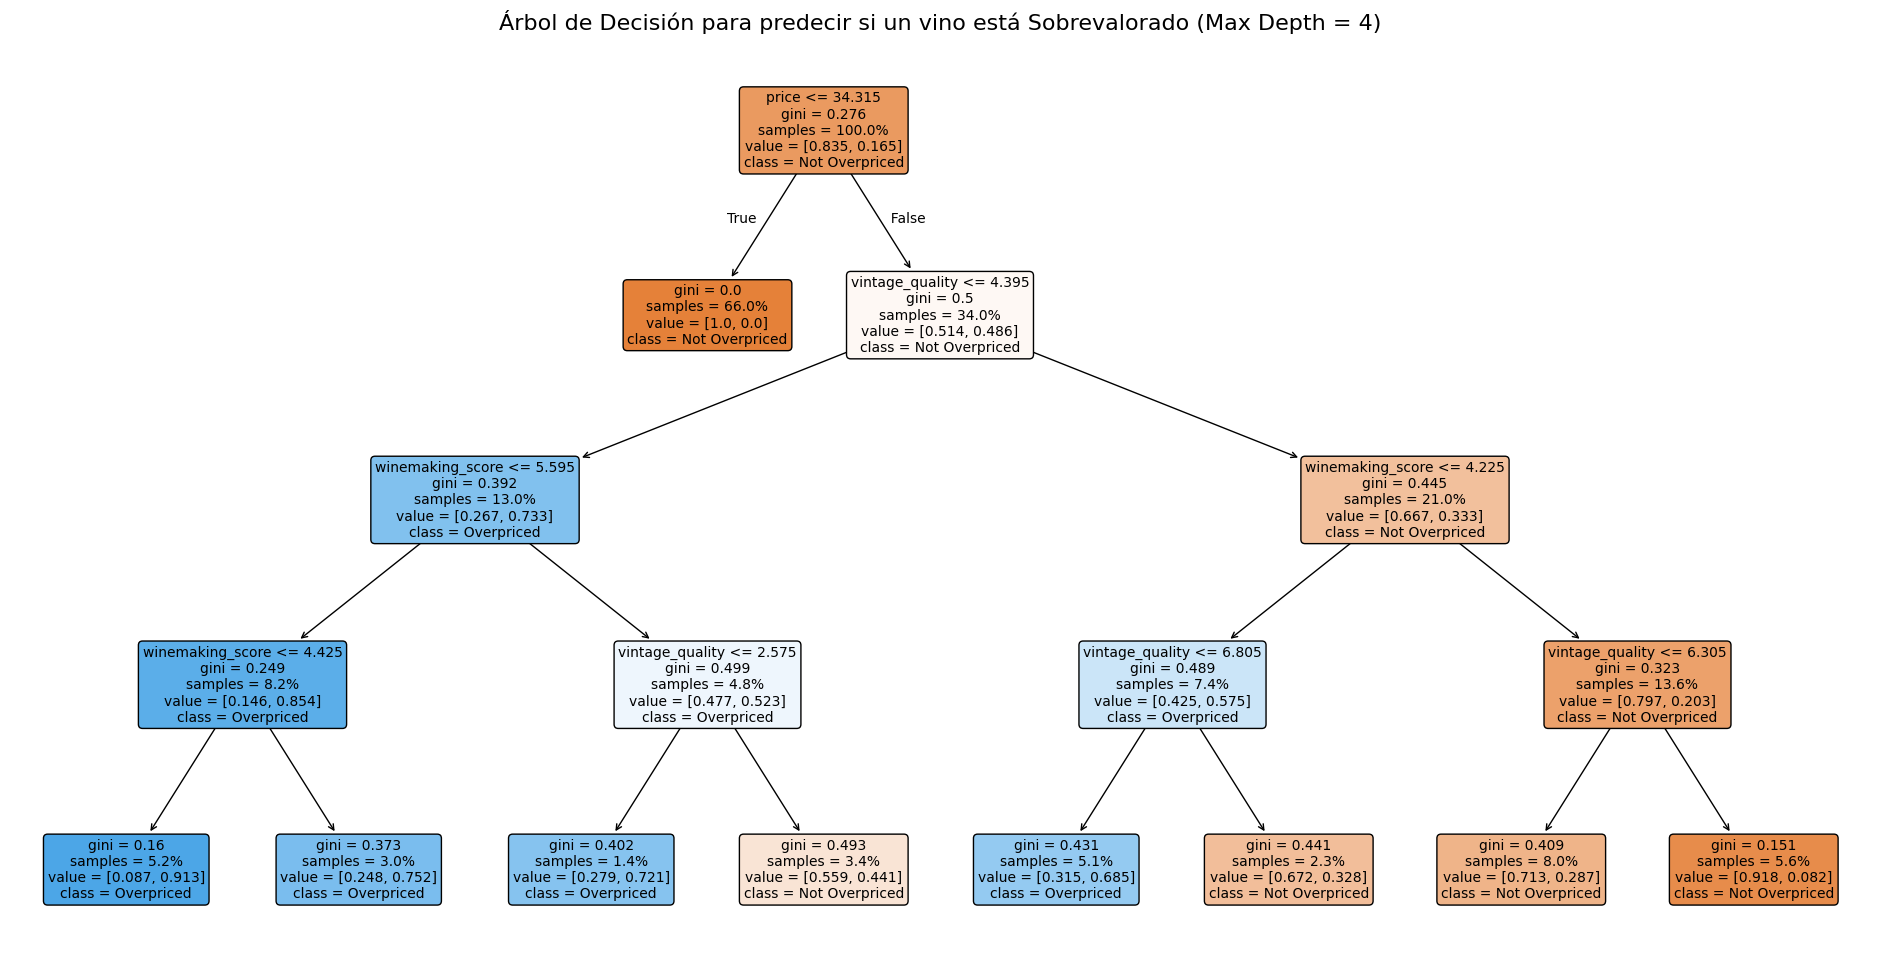

In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
import matplotlib.pyplot as plt

# 1. Elección de la variable objetivo
y = df['overpriced']

# 2. Descarte de columnas (evitando Fuga de Información)
# Eliminamos el identificador (wine_id) y TODAS las variables relacionadas a la calificación
# para obligar al árbol a buscar patrones en el origen y la elaboración del vino, no en su puntaje.
columnas_a_descartar = ['wine_id', 'overpriced', 'sighted_rating', 'value_wine',
                        'true_quality', 'blind_rating', 'blind_rating_expert', 'blind_rating_novice']
X_raw = df.drop(columns=columnas_a_descartar)

# Transformamos las variables categóricas a numéricas (One-Hot Encoding) para scikit-learn
X = pd.get_dummies(X_raw, drop_first=True)

# 3. Entrenamiento del Árbol de Decisión
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X, y)

# 4. Versión en reglas de texto
print("--- REGLAS DEL ÁRBOL EN TEXTO ---")
print(export_text(clf, feature_names=list(X.columns)))

# 5. Gráfico del árbol de decisión
plt.figure(figsize=(24, 12))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=['Not Overpriced', 'Overpriced'],
    filled=True,
    rounded=True,
    fontsize=10,
    # Usamos colores que le den un estilo profesional (como en el Lab 01)
    label='all', proportion=True
)
plt.title("Árbol de Decisión para predecir si un vino está Sobrevalorado (Max Depth = 4)", fontsize=16)
plt.show()

**Interpretación del Árbol de Decisión**
*   **Variable objetivo y descartes:** Se eligió `overpriced` como objetivo. Es vital destacar que se descartaron las variables `blind_rating`, `sighted_rating`, `blind_rating_expert`, `blind_rating_novice` y `true_quality`. Esto se hizo para evitar la **fuga de información (data leakage)**, ya que el sobreprecio se define matemáticamente en función de esas catas. Si se incluían, el árbol haría "trampa" y no generaría conocimiento del negocio.
*   **Atributo raíz:** El algoritmo eligió `price <= 34.32` como nodo raíz porque es el que otorga la mayor ganancia de información. Nos dice que los vinos baratos (menores a $34) no caen en la categoría de sobrevalorados.
*   **Reglas de negocio (Caminos detectados):**
    1. **SI** el vino es caro (`price > 34.32`) **Y** proviene de una añada de mala calidad (`vintage_quality <= 4.39`) **Y** la técnica de vinificación no es la mejor (`winemaking_score <= 5.60`), **ENTONCES** se clasifica como **Overpriced** (1).
    2. **SI** el vino es caro (`price > 34.32`) **PERO** es de una añada excelente (`vintage_quality > 6.31`), **ENTONCES** se clasifica como **Not Overpriced** (0), ya que su calidad justifica el precio.
*   **Profundidad:** Se eligió `max_depth = 4` para que las reglas resultantes sean fácilmente comprensibles por un analista de negocios y para evitar el sobreajuste (*overfitting*).

* **Qué decisión podría apoyar el árbol**: Podría integrarse en el sistema de un supermercado o tienda de licores para rechazar automáticamente lotes de vinos de proveedores si el precio propuesto es alto pero el año de cosecha (vintage) fue malo.

* **Por qué elegí esa profundidad y qué pasaría si fuera mayor:** Elegí max_depth = 4 porque mantiene el árbol lo suficientemente pequeño como para que un gerente de negocios pueda leerlo y entenderlo fácilmente. Si usara un árbol mucho más profundo (ej. max_depth = 15), ocurriría un problema de sobreajuste (overfitting): el árbol empezaría a memorizar datos irrelevantes de filas específicas, creando ramas demasiado complejas que no se podrían generalizar a nuevas botellas de vino.

Fase CRISP-DM: Preparación de los datos (descarte de columnas, dummies) y Modelado (árbol de decisión)

#F) Síntesis y procesos CRISP-DM


### **Parte F - Síntesis y proceso CRISP-DM**

**Comparación de representaciones del conocimiento**
*   **Reglas de Asociación:** Útiles para encontrar patrones ciegos, pero el hecho de tener que discretizar el precio hace perder matices numéricos. Sirve para ver el panorama general.
*   **Árbol de Decisión:** Mucho más efectivo para este dataset en particular, ya que teníamos un objetivo claro (`overpriced`). Su desventaja es el alto riesgo de sufrir fuga de información si el dataset no es limpiado con cuidado.

| Fase CRISP-DM | Aplicación en el Proyecto | Ubicación en Guía |
| :--- | :--- | :--- |
| **Comprensión del Negocio** | Identificar la necesidad de evitar engaños comerciales al comprar vinos evaluando su calidad a ciegas vs el precio público. | Parte A |
| **Comprensión de Datos** | Revisión de estructura, nulos y visualización del sesgo de los precios. | Partes B y C |
| **Preparación de Datos** | Discretización (One-Hot) y descarte de "ratings" (control de fuga de info). | Partes C, D y E |
| **Modelado** | Uso de algoritmos Apriori (soporte de 5%) y CART (profundidad 4). | Partes D y E |
| **Evaluación** | Análisis del *Lift* en reglas y de las rutas de ganancia de información en el árbol. | Partes D, E y F |
| **Despliegue** | *Propuesta:* Integrar el árbol en el ERP del comprador de supermercados para clasificar el riesgo de un nuevo lote. | Parte F |

Fase CRISP-DM: esta parte revisa todas las fases (con foco en Evaluación y Despliegue)

#G) Autoría y uso de herramientas

### **Parte G - Autoría y uso de herramientas**
*   **Enlace a GitHub:** https://github.com/vySebas/EvaluacionMineriaDeDatos
*   **Declaración de autoría:** El análisis, interpretación funcional y control de los datos (como el descarte por fuga de información) es de mi completa autoría.
*   **Uso de IA generativa:** Se usó para generar la plantilla base del código de `mlxtend` (reglas) y `scikit-learn` (árboles).
*   **Fuente:** Nefedov, S. *Wine Price vs. Blind Quality—Do You Pay for Taste?* Kaggle.
*   **Aprendizaje principal:** La fase de preparación de datos es crítica; aprendí a evitar la fuga de información descartando columnas que daban la respuesta al modelo sin esfuerzo, forzándolo así a buscar patrones reales en el origen y producción del vino.

Fase CRISP-DM: cierre y documentación del proyecto